## 1. Load data from Supabase

In [10]:
from sqlalchemy import create_engine
import pandas as pd
import os
from dotenv import load_dotenv

load_dotenv()

host = os.getenv("SUPABASE_HOST")
user = os.getenv("SUPABASE_USER")
password = os.getenv("SUPABASE_PASSWORD")

engine = create_engine(f"postgresql+psycopg2://{user}:{password}@{host}:6543/postgres")

query = """
    SELECT
        a.activity_name, a.start_date, a.activity_type,
        a.distance, a.duration, a.elevation,
        a.max_speed, a.avg_speed, a.avg_heartrate,
        a.suffer_score, a.avg_watts, a.kilojoules,
        a.start_lat, a.start_lng, a.end_lat, a.end_lng
    FROM activities a
    JOIN athletes ath ON a.athlete_id = ath.id
    ORDER BY a.start_date DESC
"""

df = pd.read_sql(query, engine)
df["start_date"] = pd.to_datetime(df["start_date"])

splits_query = """
    SELECT
        s.id AS split_id,
        s.activity_id,
        s.split_number,
        s.distance_km,
        s.elapsed_time_s,
        s.moving_time_s,
        s.elevation_diff_m,
        s.avg_speed_kmh,
        s.avg_heartrate,
        s.pace_zone,
        a.activity_name,
        a.start_date,
        a.activity_type
    FROM splits s
    JOIN activities a ON s.activity_id = a.id
    ORDER BY a.start_date DESC, s.split_number ASC
"""

df_splits = pd.read_sql(splits_query, engine)
df_splits["start_date"] = pd.to_datetime(df_splits["start_date"])

In [11]:
## Check df variables for Strava

import json
print(df)

              activity_name          start_date activity_type  distance  \
0    Amsterdam Marathon ❌❌❌ 2026-10-18 09:18:48           Run   42.7076   
1             Shake Out Run 2026-10-16 11:52:06           Run    4.0050   
2                  Base Run 2026-10-14 11:28:00           Run    4.0308   
3              Recovery Run 2026-10-13 19:40:09           Run    4.0051   
4              Morning Swim 2026-10-12 07:49:12          Swim    1.0000   
..                      ...                 ...           ...       ...   
417           Afternoon Run 2021-10-05 17:07:34           Run   10.0050   
418           Afternoon Run 2021-10-03 16:11:24           Run    4.7939   
419               Lunch Run 2021-09-28 12:42:38           Run    5.1245   
420             Morning Run 2021-09-25 09:04:20           Run    4.9394   
421             Evening Run 2021-09-22 18:02:29           Run   10.1129   

       duration  elevation  max_speed  avg_speed  avg_heartrate  suffer_score  \
0    222.066667   

In [12]:
import pandas as pd
import os
from dotenv import load_dotenv
load_dotenv()

df_fitnotes = pd.read_csv(os.getenv("FITNOTES_CSV"))
print(df_fitnotes.info())
print(df_fitnotes.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9223 entries, 0 to 9222
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9223 non-null   object 
 1   Exercise       9223 non-null   object 
 2   Category       9223 non-null   object 
 3   Weight         8407 non-null   float64
 4   Weight Unit    8407 non-null   object 
 5   Reps           8402 non-null   float64
 6   Distance       676 non-null    float64
 7   Distance Unit  676 non-null    object 
 8   Time           810 non-null    object 
dtypes: float64(3), object(6)
memory usage: 648.6+ KB
None
         Date             Exercise Category  Weight Weight Unit  Reps  \
0  2021-04-16              Cycling   Cardio     NaN         NaN   NaN   
1  2021-04-16              Cycling   Cardio     NaN         NaN   NaN   
2  2021-04-16  EZ-Bar Skullcrusher  Triceps    15.0         kgs  10.0   
3  2021-04-16  EZ-Bar Skullcrusher  Triceps    15.0        

## 2. Visualize activity results
Plot various metrics from the Strava activities, such as distance, duration, elevation gain, and average speed over time.

Taken from the exported .csv of GymNotes, though functionality exists for Strava, incomplete running data made the graph look moh.

## 2.1 All Distance Run over Time
Every outdoor run plotted chronologically from the first recorded session to the most recent. A trend line captures the long-term direction of average run distance, with an annotation showing the monthly rate of change and the total distance gained across the full period.

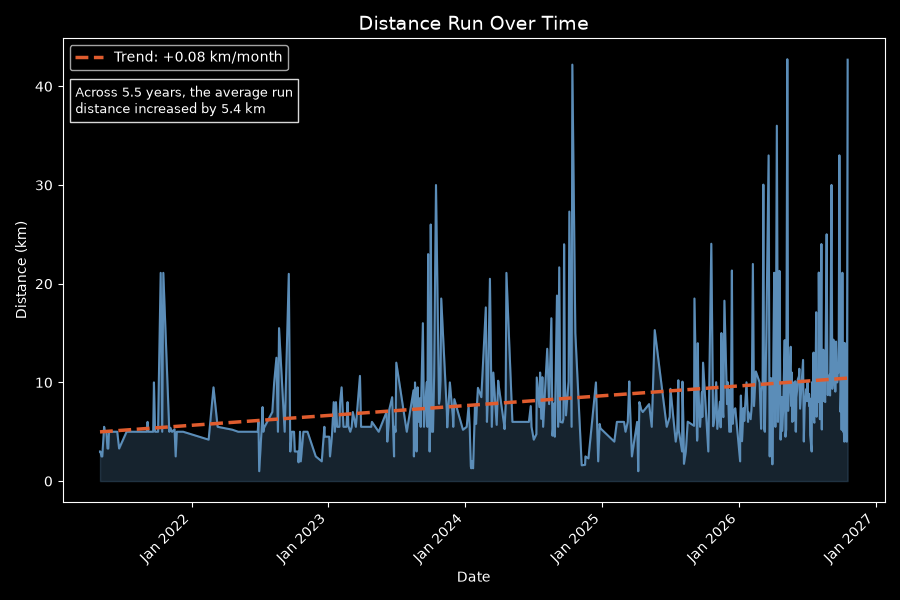

In [13]:
%matplotlib widget
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import mplcursors
from dotenv import load_dotenv
load_dotenv()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "RunAnalytics")
os.makedirs(FIGURES_DIR, exist_ok=True)

SKY_BLUE = "#5B8DB8"
SLATE    = "#E05C2E"

df_fitnotes = pd.read_csv(os.getenv("FITNOTES_CSV"))
df_fitnotes["Date"] = pd.to_datetime(df_fitnotes["Date"])

runs = (df_fitnotes[df_fitnotes["Exercise"] == "Running (Outdoor)"]
        .dropna(subset=["Distance"])
        .sort_values("Date"))

days = (runs["Date"] - runs["Date"].iloc[0]).dt.days.values
z = np.polyfit(days, runs["Distance"].values, 1)
p = np.poly1d(z)
slope_per_month = z[0] * 30.44

total_days = (runs["Date"].iloc[-1] - runs["Date"].iloc[0]).days
total_increase = z[0] * total_days
years = total_days / 365.25

fig, ax = plt.subplots(figsize=(9, 6))
line, = ax.plot(runs["Date"], runs["Distance"], linewidth=1.5, color=SKY_BLUE, zorder=3)
ax.fill_between(runs["Date"], 0, runs["Distance"], alpha=0.25, color=SKY_BLUE)
ax.plot(runs["Date"], p(days), "--", color=SLATE, linewidth=2.5, zorder=5,
        label=f"Trend: {slope_per_month:+.2f} km/month")

legend = ax.legend(loc="upper left", fontsize=10)

ax.set_title("Distance Run Over Time", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Distance (km)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

fig.canvas.draw()
bbox = legend.get_window_extent()
inv = ax.transAxes.inverted()
x0_ax, y0_ax = inv.transform([bbox.x0, bbox.y0])

note = (f"Across {years:.1f} years, the average run\n"
        f"distance increased by {total_increase:.1f} km")
ax.text(x0_ax + 0.007, y0_ax - 0.03, note, transform=ax.transAxes,
        fontsize=9, va="top", ha="left", color="white",
        bbox=dict(boxstyle="square,pad=0.4", facecolor="black", edgecolor="white", alpha=0.85))

fig.savefig(os.path.join(FIGURES_DIR, "distance_over_time.png"), dpi=150)
plt.show()

cursor = mplcursors.cursor(line, hover=False)
prev_sel = [None]

@cursor.connect("add")
def on_add(sel, p=prev_sel):
    if p[0] is not None:
        p[0].annotation.set_visible(False)
        fig.canvas.draw_idle()
    p[0] = sel
    row = runs.iloc[sel.index]
    sel.annotation.set_text(
        f"{row['Date'].strftime('%d %b %Y')}\n"
        f"Distance: {row['Distance']:.1f} km"
    )

## 2.2 Yearly Total Running Distance
Total distance accumulated per calendar year, showing how running volume has grown year-on-year. The summary panel reports lifetime totals across all recorded runs — number of sessions, cumulative distance, and total time on feet.

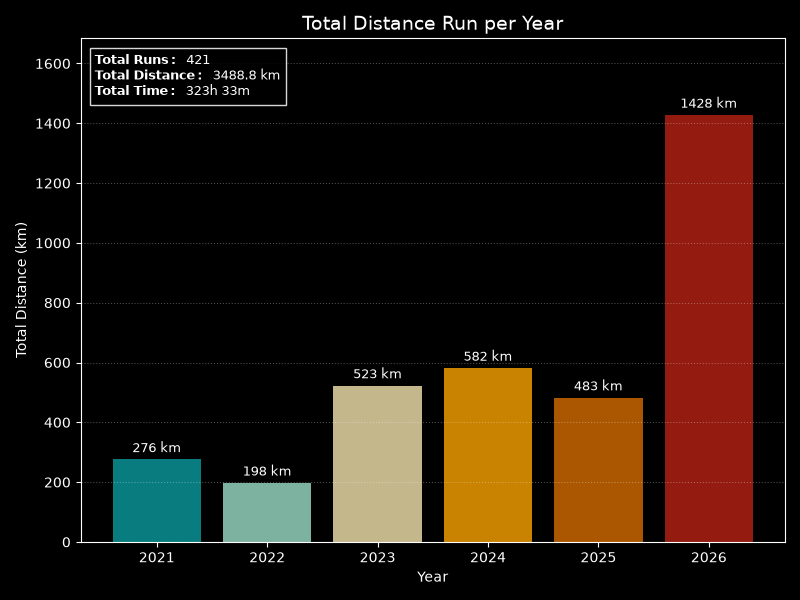

In [14]:
%matplotlib widget
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
load_dotenv()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "RunAnalytics")
os.makedirs(FIGURES_DIR, exist_ok=True)

HEATMAP0 = ["#0A9396", "#94D2BD", "#E9D8A6", "#EE9B00", "#CA6702", "#AE2012", "#9B2226"]

df_fitnotes = pd.read_csv(os.getenv("FITNOTES_CSV"))
df_fitnotes["Date"] = pd.to_datetime(df_fitnotes["Date"])

runs = (df_fitnotes[df_fitnotes["Exercise"] == "Running (Outdoor)"]
        .dropna(subset=["Distance"])
        .copy())

def parse_time_to_minutes(t):
    if pd.isna(t) or str(t).strip() == "":
        return 0
    parts = str(t).strip().split(":")
    if len(parts) == 3:
        return int(parts[0]) * 60 + int(parts[1]) + int(parts[2]) / 60
    elif len(parts) == 2:
        return int(parts[0]) + int(parts[1]) / 60
    return 0

runs["minutes"] = runs["Time"].apply(parse_time_to_minutes)
runs["year"] = runs["Date"].dt.year

yearly = runs.groupby("year")["Distance"].sum().reset_index()

total_dist = runs["Distance"].sum()
total_mins = runs["minutes"].sum()
total_hrs = int(total_mins // 60)
total_min_rem = int(total_mins % 60)
total_runs = len(runs)

colors = HEATMAP0[:len(yearly)]

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(yearly["year"].astype(str), yearly["Distance"], color=colors, alpha=0.85)
ax.set_title("Total Distance Run per Year", fontsize=14)
ax.set_xlabel("Year")
ax.set_ylabel("Total Distance (km)")
ax.set_ylim(0, yearly["Distance"].max() * 1.18)
ax.grid(axis="y", alpha=0.3, linestyle=":")

for bar, val in zip(bars, yearly["Distance"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + yearly["Distance"].max() * 0.01,
        f"{val:.0f} km",
        ha="center", va="bottom", fontsize=9, color="white", clip_on=False,
    )

summary = (
    r"$\bf{Total\ Runs:}$" + f"  {total_runs}\n"
    r"$\bf{Total\ Distance:}$" + f"  {total_dist:.1f} km\n"
    r"$\bf{Total\ Time:}$" + f"  {total_hrs}h {total_min_rem}m"
)
ax.text(0.02, 0.97, summary, transform=ax.transAxes,
        fontsize=9, va="top", ha="left", color="white",
        bbox=dict(boxstyle="square,pad=0.4", facecolor="black", edgecolor="white", alpha=0.85))

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "yearly_running_summary.png"), dpi=150)
plt.show()

## 2.3 Heart Rate vs. Pace — Aerobic Efficiency Over Time
Each point represents an easy run, plotted by average heart rate against average pace. The colour gradient maps to date, making it possible to see whether the same heart rate is producing faster paces over time — a direct signal of improving aerobic efficiency. The dashed trend line shows the overall relationship between heart rate and pace across all runs.

C:\Users\persif\AppData\Local\Temp\ipykernel_23768\802603477.py:28: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  dates_num = mdates.date2num(easy_runs["start_date"].dt.to_pydatetime())


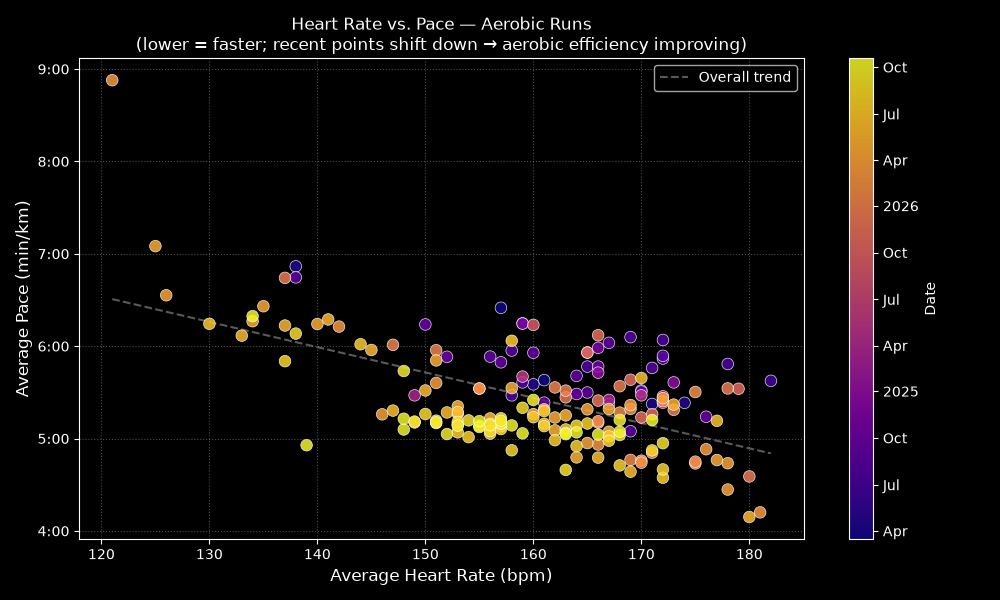

Runs plotted: 190


In [15]:
%matplotlib widget
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from dotenv import load_dotenv
load_dotenv()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "RunAnalytics")
os.makedirs(FIGURES_DIR, exist_ok=True)

EXCLUDE = r"interval|sprint|tempo|fartlek|race|hill repeat|track workout"

easy_runs = (
    df[
        (df["activity_type"] == "Run") &
        (~df["activity_name"].str.contains(EXCLUDE, case=False, na=False)) &
        df["avg_heartrate"].notna() &
        df["avg_speed"].notna()
    ]
    .sort_values("start_date")
    .copy()
)

easy_runs["pace_min_per_km"] = 60.0 / easy_runs["avg_speed"]

dates_num = mdates.date2num(easy_runs["start_date"].dt.to_pydatetime())

fig, ax = plt.subplots(figsize=(10, 6))

sc = ax.scatter(
    easy_runs["avg_heartrate"],
    easy_runs["pace_min_per_km"],
    c=dates_num,
    cmap="plasma",
    s=70,
    alpha=0.85,
    edgecolors="white",
    linewidths=0.5,
    zorder=3,
)

if len(easy_runs) >= 2:
    z = np.polyfit(easy_runs["avg_heartrate"], easy_runs["pace_min_per_km"], 1)
    p = np.poly1d(z)
    hr_range = np.linspace(easy_runs["avg_heartrate"].min(), easy_runs["avg_heartrate"].max(), 200)
    ax.plot(hr_range, p(hr_range), "--", color="gray", linewidth=1.5, alpha=0.7, label="Overall trend")
    ax.legend(fontsize=10)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Date", fontsize=10)
loc = mdates.AutoDateLocator()
cbar.ax.yaxis.set_major_locator(loc)
cbar.ax.yaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

def pace_formatter(x, _):
    mins = int(x)
    secs = int(round((x - mins) * 60))
    return f"{mins}:{secs:02d}"

ax.yaxis.set_major_formatter(plt.FuncFormatter(pace_formatter))
ax.set_xlabel("Average Heart Rate (bpm)", fontsize=12)
ax.set_ylabel("Average Pace (min/km)", fontsize=12)
ax.set_title("Heart Rate vs. Pace — Aerobic Runs\n(lower = faster; recent points shift down → aerobic efficiency improving)", fontsize=12)
ax.grid(alpha=0.3, linestyle=":")

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "hr_vs_pace_aerobic_runs.png"), dpi=150)
plt.show()

print(f"Runs plotted: {len(easy_runs)}")

## 2.4 Running Distance by Country
Total kilometres run per country, based on the GPS start coordinates recorded by Strava. Each country is shaded by cumulative distance — the darker the fill, the more ground covered there.

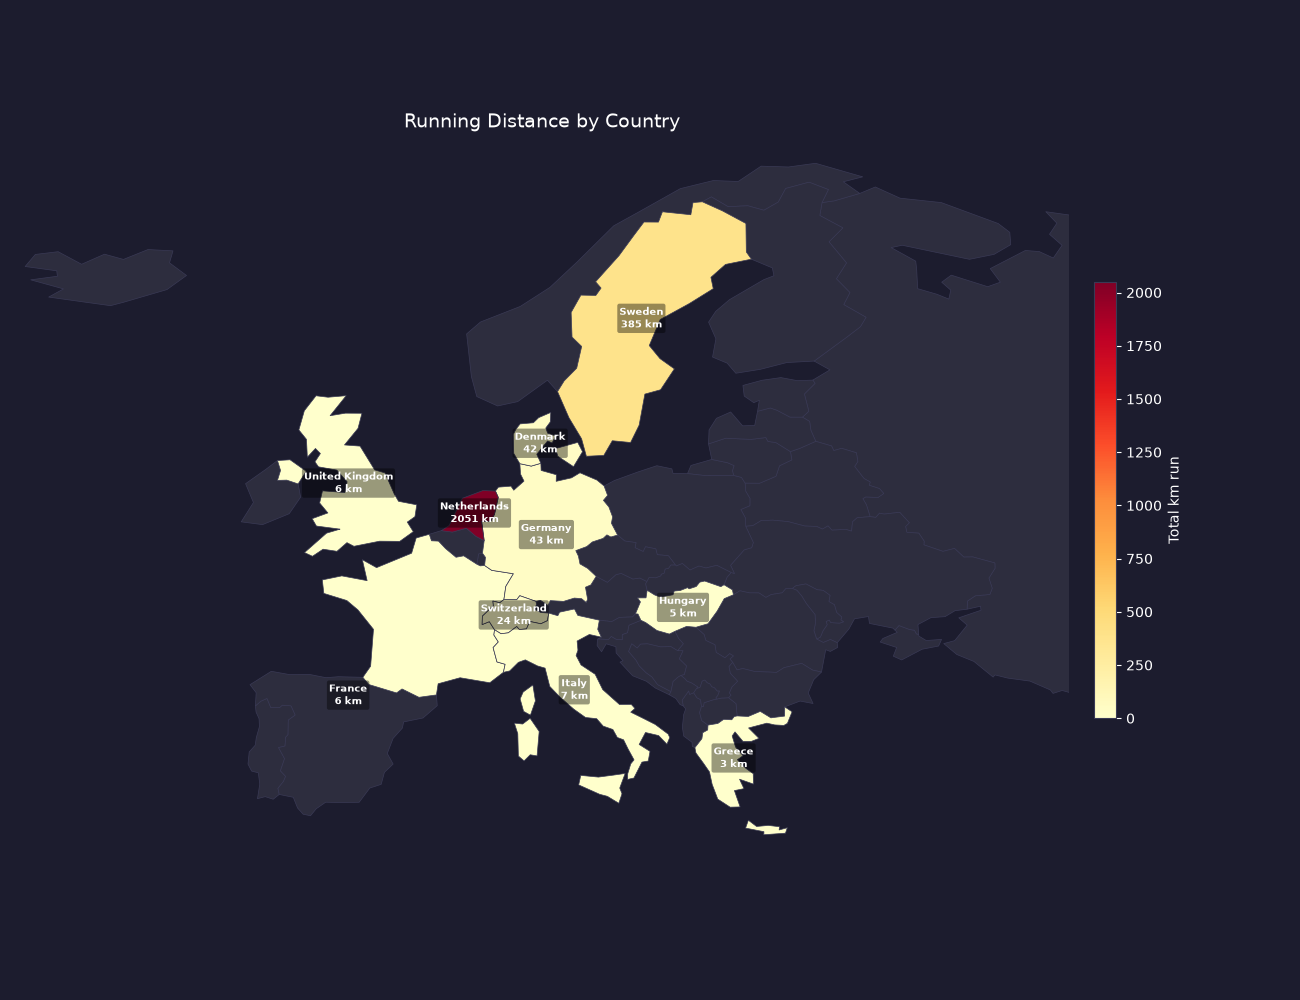

In [16]:
# Requires: pip install geopandas cartopy
# cartopy auto-downloads and caches the Natural Earth shapefile on first run

%matplotlib widget
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import geopandas as gpd
import cartopy.io.shapereader as shpreader
from dotenv import load_dotenv
load_dotenv()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "RunAnalytics")
os.makedirs(FIGURES_DIR, exist_ok=True)

# ---- Data prep ----
runs_geo = df[
    df["start_lat"].notna() & df["start_lng"].notna() &
    (df["activity_type"] == "Run")
].copy()

gdf_runs = gpd.GeoDataFrame(
    runs_geo[["distance", "start_lat", "start_lng"]],
    geometry=gpd.points_from_xy(runs_geo["start_lng"], runs_geo["start_lat"]),
    crs="EPSG:4326"
)

ne_path = shpreader.natural_earth(resolution="110m", category="cultural", name="admin_0_countries")
world = gpd.read_file(ne_path)[["NAME", "CONTINENT", "geometry"]].rename(
    columns={"NAME": "name", "CONTINENT": "continent"}
)

# Reproject to EPSG:3035 for accurate nearest-distance calculation (meters, not degrees)
gdf_runs_proj = gdf_runs.to_crs("EPSG:3035")
world_proj    = world[["name", "continent", "geometry"]].to_crs("EPSG:3035")

joined = gpd.sjoin_nearest(gdf_runs_proj, world_proj, how="left")
joined = joined[joined["continent"] == "Europe"]

country_dist = joined.groupby("name")["distance"].sum().reset_index()
country_dist.columns = ["name", "total_km"]

# Back to EPSG:4326 for plotting
europe = world[world["continent"] == "Europe"].copy()
europe = europe.merge(country_dist, on="name", how="left")
europe["total_km"] = europe["total_km"].fillna(0)

# ---- Plot ----
BG      = "#1C1C2E"
NO_DATA = "#2D2D3E"
EDGE    = "#3A3A55"

visited = europe[europe["total_km"] > 0]
vmax    = visited["total_km"].max() if len(visited) > 0 else 1
norm    = mcolors.Normalize(vmin=0, vmax=vmax)

fig, ax = plt.subplots(figsize=(13, 10))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

europe[europe["total_km"] == 0].plot(ax=ax, color=NO_DATA, edgecolor=EDGE, linewidth=0.5)

if len(visited) > 0:
    visited.plot(ax=ax, column="total_km", cmap="YlOrRd", norm=norm,
                 edgecolor=EDGE, linewidth=0.5)

    sm = cm.ScalarMappable(cmap="YlOrRd", norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.45, pad=0.02, aspect=20)
    cbar.set_label("Total km run", color="white", fontsize=10)
    cbar.ax.yaxis.set_tick_params(color="white")
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color="white")
    cbar.outline.set_edgecolor(EDGE)

    for _, row in visited.iterrows():
        centroid = row.geometry.centroid
        ax.annotate(
            f"{row['name']}\n{row['total_km']:.0f} km",
            xy=(centroid.x, centroid.y),
            ha="center", va="center",
            fontsize=7.5, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="black", alpha=0.4, edgecolor="none")
        )

ax.set_xlim(-25, 45)
ax.set_ylim(34, 72)
ax.set_axis_off()
ax.set_title("Running Distance by Country", fontsize=14, color="white", pad=15)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "europe_running_map.png"), dpi=150,
            facecolor=fig.get_facecolor())
plt.show()

## 2.5 Weekly Time in HR Zones
Time spent in each heart-rate zone per week, stacked and coloured from Z1 (easy, blue) to Z5 (VO₂max, red). The 80/20 rule of endurance training states that roughly 80% of weekly training time should sit in Z1–Z2. Imbalances — too much time in Z3–Z4 — are a common driver of accumulated fatigue and overtraining.

HRmax is estimated as the 99th-percentile of all recorded split heart rates.

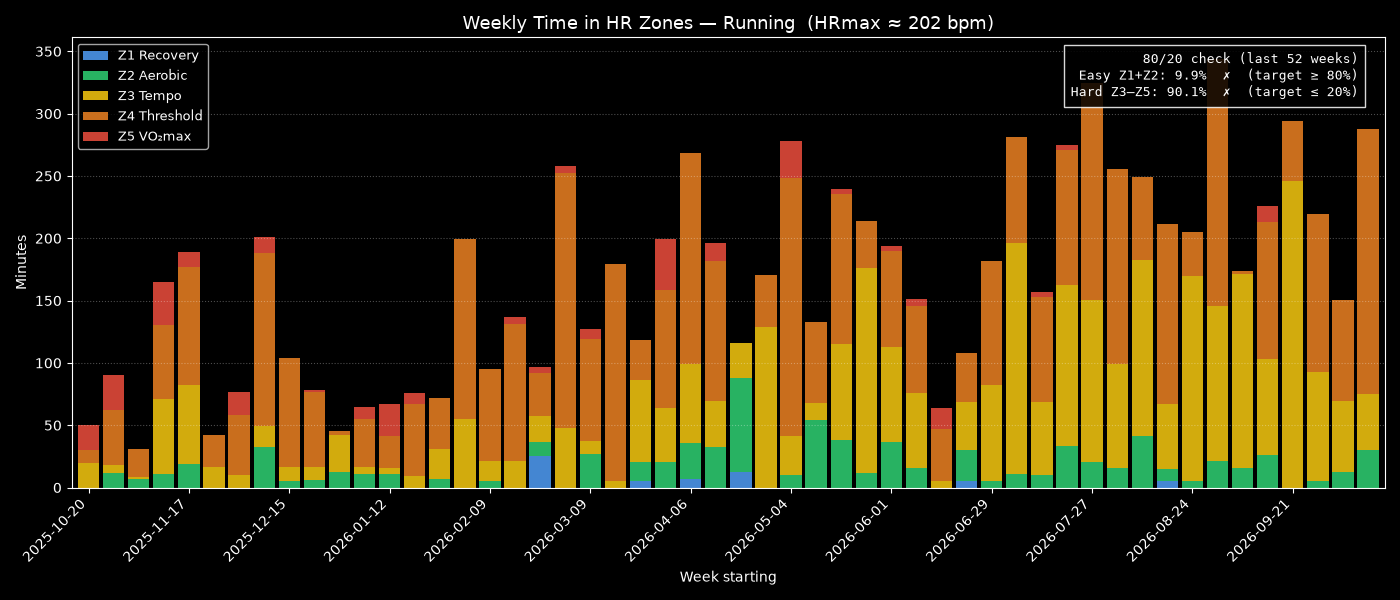

HRmax used: 202 bpm

Overall zone distribution (last 52 weeks):
  Z1 Recovery: 60 min (0.7%)
  Z2 Aerobic: 805 min (9.2%)
  Z3 Tempo: 3114 min (35.7%)
  Z4 Threshold: 4419 min (50.6%)
  Z5 VO₂max: 332 min (3.8%)

80/20 check:
  Easy (Z1+Z2): 9.9%  ✗
  Hard (Z3–Z5): 90.1%  ✗


In [17]:
%matplotlib widget
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from dotenv import load_dotenv
load_dotenv()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "RunAnalytics")
os.makedirs(FIGURES_DIR, exist_ok=True)

run_splits = df_splits[
    (df_splits["activity_type"] == "Run") &
    df_splits["avg_heartrate"].notna() &
    df_splits["moving_time_s"].notna()
].copy()

HR_MAX = 202

ZONES = [
    ("Z1 Recovery",  0.00, 0.60, "#4E9AF1"),
    ("Z2 Aerobic",   0.60, 0.70, "#2ECC71"),
    ("Z3 Tempo",     0.70, 0.80, "#F1C40F"),
    ("Z4 Threshold", 0.80, 0.90, "#E67E22"),
    ("Z5 VO₂max",    0.90, 1.01, "#E74C3C"),
]

def assign_zone(hr):
    pct = hr / HR_MAX
    for name, lo, hi, _ in ZONES:
        if lo <= pct < hi:
            return name
    return "Z5 VO₂max"

run_splits["zone"]    = run_splits["avg_heartrate"].apply(assign_zone)
run_splits["minutes"] = run_splits["moving_time_s"] / 60
run_splits["week"]    = run_splits["start_date"].dt.to_period("W").apply(lambda p: p.start_time)

weekly_zone = run_splits.groupby(["week", "zone"])["minutes"].sum().unstack(fill_value=0)

zone_order  = [z[0] for z in ZONES]
zone_colors = [z[3] for z in ZONES]
for z in zone_order:
    if z not in weekly_zone.columns:
        weekly_zone[z] = 0
weekly_zone = weekly_zone[zone_order]

cutoff = weekly_zone.index.max() - pd.DateOffset(weeks=52)
weekly_zone = weekly_zone[weekly_zone.index >= cutoff]

# 80/20 rule calculation
total_by_zone = weekly_zone.sum()
total_min     = total_by_zone.sum()
easy_pct = (total_by_zone["Z1 Recovery"] + total_by_zone["Z2 Aerobic"]) / total_min * 100
hard_pct = 100 - easy_pct
easy_ok  = easy_pct >= 80
hard_ok  = hard_pct <= 20

fig, ax = plt.subplots(figsize=(14, 6))
weekly_zone.plot(kind="bar", stacked=True, ax=ax,
                 color=zone_colors, alpha=0.88, width=0.85)

ax.set_title(f"Weekly Time in HR Zones — Running  (HRmax ≈ {HR_MAX} bpm)", fontsize=13)
ax.set_xlabel("Week starting")
ax.set_ylabel("Minutes")

tick_step = max(1, len(weekly_zone) // 13)
ax.set_xticks(range(0, len(weekly_zone), tick_step))
ax.set_xticklabels(
    [str(weekly_zone.index[i].date()) for i in range(0, len(weekly_zone), tick_step)],
    rotation=45, ha="right"
)
ax.legend(loc="upper left", fontsize=9)
ax.grid(axis="y", alpha=0.3, linestyle=":")

# 80/20 annotation box
easy_sym = "✓" if easy_ok else "✗"
hard_sym = "✓" if hard_ok else "✗"
easy_col = "#2ECC71" if easy_ok else "#E74C3C"
hard_col = "#2ECC71" if hard_ok else "#E74C3C"

annotation = (
    f"80/20 check (last 52 weeks)\n"
    f"Easy Z1+Z2: {easy_pct:.1f}%  {easy_sym}  (target ≥ 80%)\n"
    f"Hard Z3–Z5: {hard_pct:.1f}%  {hard_sym}  (target ≤ 20%)"
)
ax.text(0.98, 0.97, annotation, transform=ax.transAxes,
        fontsize=9, va="top", ha="right", color="white", family="monospace",
        bbox=dict(boxstyle="square,pad=0.5", facecolor="black", edgecolor="white", alpha=0.85))

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "hr_zone_distribution.png"), dpi=150)
plt.show()

print(f"HRmax used: {HR_MAX} bpm")
print(f"\nOverall zone distribution (last 52 weeks):")
for z, mins in total_by_zone.items():
    print(f"  {z}: {mins:.0f} min ({100*mins/total_min:.1f}%)")
print(f"\n80/20 check:")
print(f"  Easy (Z1+Z2): {easy_pct:.1f}%  {easy_sym}")
print(f"  Hard (Z3–Z5): {hard_pct:.1f}%  {hard_sym}")

## 2.6 Suffer Score Efficiency
Suffer score per kilometre for every scored run, plotted over time. A downward trend means the same distance produces less perceived effort — a direct signal of improving fitness. The 30-day rolling average (cream line) smooths session-to-session variation, and the dashed trend line shows the long-run direction.

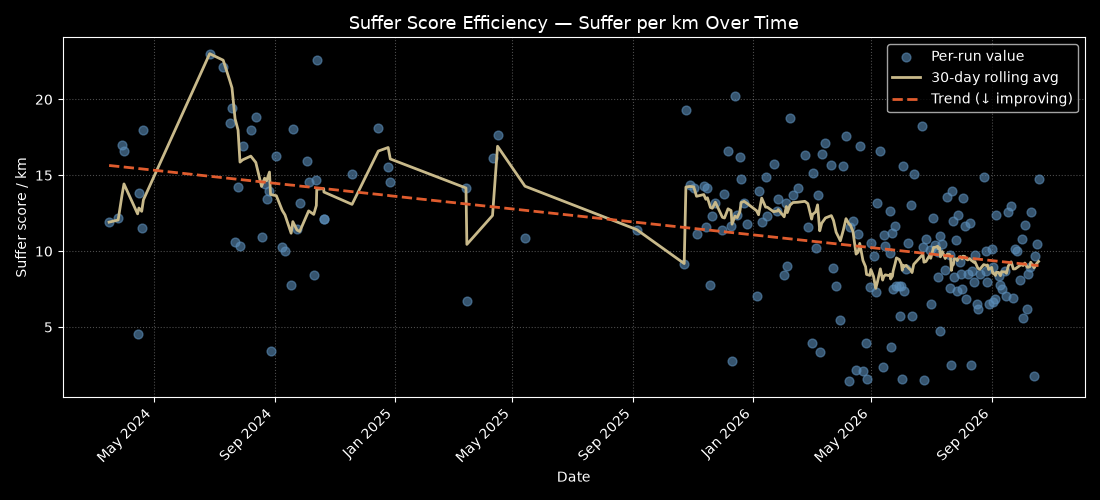

Runs with suffer score: 205
Average suffer/km: 11.09
Recent trend: ↓ improving


In [18]:
%matplotlib widget
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from dotenv import load_dotenv
load_dotenv()

FIGURES_DIR = os.path.join(os.getenv("FIGURES_DIR"), "RunAnalytics")
os.makedirs(FIGURES_DIR, exist_ok=True)

SKY_BLUE = "#5B8DB8"
SLATE    = "#E05C2E"
CREAM    = "#C8B98A"

eff = (
    df[
        (df["activity_type"] == "Run") &
        df["suffer_score"].notna() &
        (df["distance"] > 3)
    ]
    .copy()
    .sort_values("start_date")
    .reset_index(drop=True)
)

eff["suffer_per_km"] = eff["suffer_score"] / eff["distance"]

eff_indexed = eff.set_index("start_date")
rolling = eff_indexed["suffer_per_km"].rolling("30D").mean().values

days = (eff["start_date"] - eff["start_date"].iloc[0]).dt.days.values
z = np.polyfit(days, eff["suffer_per_km"].values, 1)
p = np.poly1d(z)
trend_dir = "↓ improving" if z[0] < 0 else "↑ increasing"

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(eff["start_date"], eff["suffer_per_km"],
           color=SKY_BLUE, s=40, alpha=0.6, zorder=3, label="Per-run value")
ax.plot(eff["start_date"], rolling, color=CREAM, linewidth=2, zorder=4, label="30-day rolling avg")
ax.plot(eff["start_date"], p(days), "--", color=SLATE, linewidth=2, zorder=5,
        label=f"Trend ({trend_dir})")

ax.set_title("Suffer Score Efficiency — Suffer per km Over Time", fontsize=13)
ax.set_xlabel("Date")
ax.set_ylabel("Suffer score / km")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
plt.xticks(rotation=45, ha="right")
ax.legend(fontsize=10)
ax.grid(alpha=0.3, linestyle=":")

plt.tight_layout()
fig.savefig(os.path.join(FIGURES_DIR, "suffer_score_efficiency.png"), dpi=150)
plt.show()

print(f"Runs with suffer score: {len(eff)}")
print(f"Average suffer/km: {eff['suffer_per_km'].mean():.2f}")
print(f"Recent trend: {trend_dir}")